
# 08 时间序列与波动率：从随机漫步到 GARCH

> **本章要解决的问题**：价格看起来有趋势，为什么不能预测？波动率看不见，为什么反而可以预测？一条均线、一个 GARCH 模型，到底在算什么？

## 本章导读

第02章讲的是“一批独立的结果”。这一章讲“一串按时间排列的结果”：今天的价格依赖昨天，昨天的波动影响今天。时间顺序带来两个新问题：

1. **不能打乱顺序**。把日期随机打乱，均线、自相关、GARCH 全部失效；
2. **不能偷看未来**。用全样本均值、全样本分位数、事后才知道的状态，都会让回测虚高。

本章分九节：

1. 四个基本对象：价格、收益、时间戳、采样；
2. 随机漫步：为什么“看起来有趋势”不等于“可以预测”；
3. 平稳性与 ADF：什么时候可以用历史均值；
4. 自相关：今天和昨天有没有关系；
5. AR(1) 与均值回归：偏离中心后，下一步会怎样；
6. 移动平均与 EWMA：均线为什么滞后；
7. 协整：两条非平稳价格，什么时候可以配对；
8. GARCH：波动率为什么成簇，怎样预测；
9. 频谱与周期：怎样从数据里量出节奏。

### 学习目标

- 能对收益序列做平稳性、ACF、偏自相关检查。
- 能拟合 AR/OU/GARCH，并解释参数和半衰期。
- 能用滚动窗口做样本外波动率预测。
- 能识别中心化滚动、未来数据、重叠样本。
- 能把波动率预测用于仓位或风险限额。

### 先修

第02章的期望、方差、正态分布、标准误；会用 pandas 的 `rolling`、`resample`；不需要随机微积分（第06章会补）。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="08 时间序列与波动率：从随机漫步到 GARCH" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>08 时间序列与波动率：从随机漫步到 GARCH｜知识图</title>
<desc>本章主线：价格像随机漫步，波动率却成簇可预测；先查平稳性，再做滚动样本外。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a04" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao04" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag04" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">08</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">时间序列与波动率：从随机漫步到 GARCH</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：价格像随机漫步，波动率却成簇可预测；先查平稳性，再做滚动样本外。</text>
<rect x="41" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="121" y="141.3" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">分钟 / 日价格序列</text>
<text x="121" y="161.4" font-size="10.5" fill="#6E7B8B" text-anchor="middle">时间戳、采样、交易节</text>
<rect x="51" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="68" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">输入</text>
<rect x="227" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="307" y="132.1" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">对数收益 · ACF ·</text>
<text x="307" y="150.6" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">AR/GARCH</text>
<text x="307" y="170.6" font-size="10.5" fill="#6E7B8B" text-anchor="middle">平稳性与残差诊断</text>
<rect x="237" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="254" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">处理</text>
<rect x="413" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="493" y="141.3" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">波动率预测与半衰期</text>
<text x="493" y="161.4" font-size="10.5" fill="#6E7B8B" text-anchor="middle">参数、区间、情景</text>
<rect x="423" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="440" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">输出</text>
<rect x="599" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="679" y="132.1" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">滚动样本外 + 无未来</text>
<text x="679" y="150.6" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">数据</text>
<text x="679" y="170.6" font-size="10.5" fill="#6E7B8B" text-anchor="middle">不许打乱、不许中心化滚动</text>
<rect x="609" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="626" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">检查</text>
<path d="M 201 149 L 227 149" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a04)"/>
<path d="M 387 149 L 413 149" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a04)"/>
<path d="M 573 149 L 599 149" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a04)"/>
<rect x="41" y="232" width="718" height="152" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<rect x="58" y="246" width="4" height="11" fill="#E07B39" rx="1"/>
<text x="70" y="256" font-size="11.5" fill="#1B3A5C" font-weight="bold">价格 vs 波动率：该预测的是后者</text>
<text x="58" y="278" font-size="9.5" fill="#6E7B8B">价格：像随机漫步</text>
<path d="M 150 308.9 L 168 314.5 L 186 306.8 L 204 316.6 L 222 311.7 L 240 303.3 L 258 311 L 276 307.5 L 294 313.8 L 312 304 L 330 308.2 L 348 301.9 L 366 310.3 L 384 307.5 L 402 300.5 L 420 305.4 L 438 301.2 L 456 310.3 L 474 301.9 L 492 304.7" fill="none" stroke="#1B3A5C" stroke-width="1.4" stroke-linecap="round" stroke-linejoin="round"/>
<line x1="150" y1="330" x2="480" y2="330" stroke="#E6EFF7" stroke-width="1.4" stroke-linecap="round"/>
<text x="58" y="344" font-size="9.5" fill="#6E7B8B">波动率：成簇、可预测</text>
<path d="M 150 355.8 L 172 357.6 L 194 352.2 L 216 345 L 238 325.2 L 260 336 L 282 348.6 L 304 352.2 L 326 341.4 L 348 319.8 L 370 328.8 L 392 345 L 414 350.4 L 436 339.6 L 458 354 L 480 355.8" fill="none" stroke="#E07B39" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 150 372 L 492 372" fill="none" stroke="#6E7B8B" stroke-width="1.1" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag04)"/>
<rect x="540" y="277" width="4" height="9" fill="#E07B39" rx="1"/>
<text x="550" y="286" font-size="10" fill="#1B3A5C">√t 缩放：波动按时间开方</text>
<rect x="540" y="307" width="4" height="9" fill="#E07B39" rx="1"/>
<text x="550" y="316" font-size="10" fill="#1B3A5C">GARCH(1,1)：波动有记忆</text>
<rect x="540" y="337" width="4" height="9" fill="#E07B39" rx="1"/>
<text x="550" y="346" font-size="10" fill="#1B3A5C">滚动预测：只看当时信息</text>
</svg>

> **图**：本章主线：价格像随机漫步，波动率却成簇可预测；先查平稳性，再做滚动样本外。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：时序研究员、风控、波动率交易。
- **输入**：分钟或日收益序列。
- **输出**：波动率预测、半衰期、回归/AR/GARCH 参数。
- **在流程的哪一步**：风险建模与特征工程。
- **失败模式**：中心化滚动、用未来数据、样本外不滚动、GARCH 不收敛还硬用。
- **最小工作流**：平稳性/ACF → AR/OU/GARCH → 残差诊断 → 滚动预测 → 回测。

---
## 1. 四个基本对象：价格、收益、时间戳、采样

### 1.1 价格是水平，收益是变化

设 $P_t$ 是第 $t$ 期的收盘价。最简单的收益是

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}}.$$

更常用的是对数收益：

$$r_t=\ln\frac{P_t}{P_{t-1}}=\ln P_t-\ln P_{t-1}.$$

对数收益的好处：

- 可加：两天的对数收益相加，等于两天的总对数收益；
- 对称：涨 10% 再跌 10%，算术收益是 $-1\%$，对数收益是 $\ln(1.1)+\ln(0.9)=\ln(0.99)\approx-1.005\%$，方向清楚；
- 近似百分比：$r$ 很小时，$\ln(1+r)\approx r$。

**价格是非平稳的，收益通常近似平稳。** 这句话是本章的分水岭：价格的水平会随时间漂移，均值和方差都不是常数；收益的均值和方差相对稳定，才适合用历史数据估计。

### 1.2 时间戳：一根 K 线什么时候才算结束

分钟线有“开始时间”和“结束时间”两种标法。用开始时间标记，最新一根可能还没走完；用结束时间标记，才能保证“这根线已经结束”。

合成 5 分钟线时：

- 开盘价取第一根 1 分钟的开盘；
- 最高价取五根的最高；
- 最低价取五根的最低；
- 收盘价取第五根的收盘；
- 成交量求和。

如果中间缺了一根，这根 5 分钟线就不完整。**缺失不能当 0，也不能用前值硬填**；要么标记缺失，要么跳过。

### 1.3 代码：从 1 分钟到 5 分钟



In [2]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(401)
idx = pd.date_range("2026-11-02 09:01", periods=120, freq="min")
price = 3000 + np.cumsum(rng.normal(0, 1, size=len(idx)))
minute = pd.DataFrame({"close": price}, index=idx)

bars = minute.resample("5min", closed="right", label="right").agg(
    {"close": ["first", "max", "min", "last"]}
)
bars.columns = ["open", "high", "low", "close"]
bars = bars.dropna()
bars["log_ret"] = np.log(bars["close"]).diff()

print(bars.head(4).round(3))
print("5 分钟线数量", len(bars), "缺失值", int(bars.isna().sum().sum()))


                         open      high       low     close  log_ret
2026-11-02 09:05:00  2999.153  3000.161  2998.711  2998.711      NaN
2026-11-02 09:10:00  2997.070  2999.566  2997.070  2999.560    0.000
2026-11-02 09:15:00  3001.174  3001.457  3000.418  3000.418    0.000
2026-11-02 09:20:00  3000.806  3000.806  2998.356  2998.356   -0.001
5 分钟线数量 24 缺失值 1



**读数与应用**：`closed="right"`、`label="right"` 表示用区间右端标记这根线，09:00–09:05 的线记作 09:05。这样在 09:05 收盘后，你才知道这根线；如果标成 09:00，就会在 09:00 用上 09:05 的信息。

**常见错误**：

1. 用 09:00 标记 09:00–09:05 的线，然后在 09:00 下单。这是未来函数。
2. 把缺失的 5 分钟线当成“价格没变”。成交量、波动率都会失真。
3. 用价格的差分当收益。价格 3000 和 30 的“涨 1 元”完全不是一回事。

**停下来想一想**：为什么对数收益比简单收益更适合做跨品种比较？

<details><summary>对照你的思路</summary>

简单收益的分母是上一期价格；价格水平不同的品种，“涨 1%”对应的绝对金额不同，但简单收益本身已经归一化了。对数收益的好处主要是可加、对称，且与连续复利对应。跨品种比较时，两者都可以用，但要在同一口径上；不要一会儿用简单收益、一会儿用对数收益。

</details>

### 1.4 采样与对齐的三个坑

1. **收盘价 vs 结算价**：商品期货的结算价不是收盘价。回测用哪个，要和交易规则、保证金计算一致。
2. **夜盘归属**：夜盘属于下一个交易日；把夜盘算到前一天，会把隔夜信息错配。
3. **缺失与停牌**：缺失一根，不等于价格不变；用前值填充会人为制造零收益，压低波动率。

一个检查办法：把每个交易日的分钟数打印出来，和交易所的时段表对一遍。数量不对，先修数据，再谈模型。

---



## 2. 随机漫步：为什么看起来有趋势，却不能预测

### 2.1 定义

最朴素的随机漫步：

$$P_t=P_{t-1}+\epsilon_t,\qquad \epsilon_t\sim N(0,\sigma^2)\text{ 独立同分布}.$$

每一步的冲击不可预测，但价格水平会把过去所有冲击累积起来。于是：

$$P_t=P_0+\sum_{i=1}^t \epsilon_i,$$

$$E[P_t]=P_0,\qquad \operatorname{Var}(P_t)=t\sigma^2,\qquad \operatorname{SD}(P_t)=\sigma\sqrt t.$$

**方差随时间线性增长，标准差按 $\sqrt t$ 增长。** 这就是为什么“拿住不动”的风险会随时间变大，但不是线性变大。

### 2.2 两步手算

从 100 出发，每步 $\pm1$，概率各一半。两步后的终值：

| 路径 | 终值 | 概率 |
|---|---:|---:|
| $+1,+1$ | 102 | 1/4 |
| $+1,-1$ | 100 | 1/4 |
| $-1,+1$ | 100 | 1/4 |
| $-1,-1$ | 98 | 1/4 |

均值 100，方差 $2$，标准差 $\sqrt2$。三步的方差是 3，$n$ 步是 $n$。

### 2.3 为什么图上有“趋势”

随机漫步的路径经常出现连续上涨、连续下跌，看起来像趋势。但这些“趋势”是事后视觉，不是可预测的信号：给定今天，下一步的期望仍是今天的价格。

这也解释了为什么很多趋势策略在样本内很漂亮、样本外失效：它们可能只是在对随机漫步的局部形状做拟合。

### 2.4 代码：路径与方差



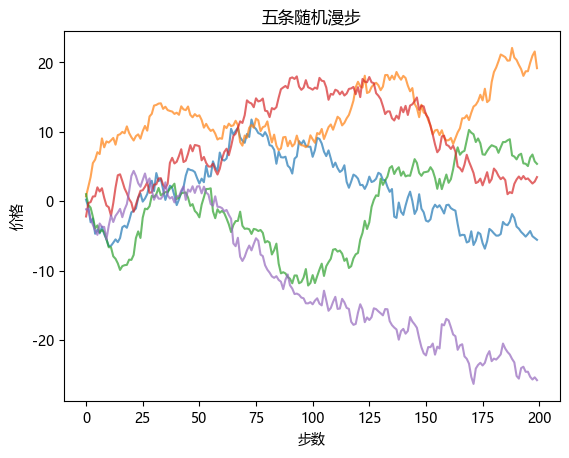

第 200 步的样本方差 201.2 理论值 200


In [3]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(402)
n = 200

paths = np.cumsum(rng.normal(0, 1, size=(5, n)), axis=1)
plt.plot(paths.T, alpha=0.7)
plt.title("五条随机漫步")
plt.xlabel("步数")
plt.ylabel("价格")
plt.show()

many = np.cumsum(rng.normal(0, 1, size=(20_000, n)), axis=1)
print("第 200 步的样本方差", round(many[:, -1].var(ddof=1), 1), "理论值", n)



**读数与应用**：五条路径有的向上、有的向下，看起来各有“趋势”；但第 200 步的方差接近 200，说明分散度按理论增长。**路径的形状不等于可预测性。**

**常见错误**：

1. 看到一段连续上涨，就说“趋势确认”。在随机漫步里，连续上涨很常见。
2. 用价格水平做回归，得到很高的 $R^2$，就以为找到了关系。两个独立随机漫步回归，$R^2$ 也可能很高，这是伪回归。
3. 把“方差随时间增长”理解成“风险按时间线性增长”。标准差是按 $\sqrt t$ 增长。

**停下来想一想**：随机漫步里，价格和收益哪个是平稳的？

<details><summary>对照你的思路</summary>

收益 $\epsilon_t$ 是独立同分布的，均值 0、方差 $\sigma^2$，是平稳的；价格是收益的累积和，方差随时间增长，不平稳。所以做统计检验时，通常对收益做，不对价格做。第 3 节会把这个直觉变成 ADF 检验。

</details>

### 2.5 随机漫步作为基准

随机漫步不是“市场一定有效”，而是一个**零假设**：如果价格是随机漫步，任何趋势策略都不应该有超额收益。回测时，把策略和“买入持有”或“随机入场”比较；如果只比 0，容易把市场整体的上涨当成策略的本事。

一个实用的对照：

- 同一品种、同一时段、同一成本；
- 随机入场同样次数、同样持仓时间；
- 重复 1,000 次，看策略收益在随机分布的哪个分位。

如果策略只比随机好一点，先别急着上线。

---



## 3. 平稳性与 ADF：什么时候可以用历史均值

### 3.1 两种平稳

**严平稳**：任意平移时间，联合分布不变。

**弱平稳**：均值、方差不随时间变，协方差只依赖时间间隔：

$$E[x_t]=\mu,\qquad \operatorname{Var}(x_t)=\sigma^2,\qquad \operatorname{Cov}(x_t,x_{t-k})=\gamma_k.$$

弱平稳是大多数时间序列方法的前提。价格通常不满足（均值会漂移），收益通常近似满足。

### 3.2 单位根与 ADF

考虑 AR(1)：

$$x_t=\phi x_{t-1}+\epsilon_t.$$

若 $|\phi|<1$，冲击会衰减，序列围绕均值波动，是平稳的；若 $\phi=1$，冲击永久累积，是单位根，不平稳。

检验 $\phi=1$，等价于对

$$\Delta x_t=\beta x_{t-1}+\epsilon_t$$

检验 $\beta=0$。ADF 在此基础上加入滞后项，吸收短期相关：

$$\Delta x_t=\alpha+\beta x_{t-1}+\sum_{i=1}^p\gamma_i\Delta x_{t-i}+\epsilon_t.$$

**公式拆解**
- **符号**：$x_t$ 序列，$\Delta x_t$ 差分，$\beta$ 水平项系数，$\alpha$ 漂移，$p$ 滞后阶。
- **结构**：右边是漂移、水平项与滞后差分；关键 $\beta=\phi-1$，检验 $\beta=0$ 即单位根。
- **代入**：$x=(0,1,0,2,1,1.5)$：$\hat\beta=-0.42$，$t=-0.77$，不能拒绝单位根。
- **边界**：$\beta<0$ 平稳；临界值约 $-1.95$ 到 $-3.41$，不能用 1.96。
- **用途**：判断能否用历史均值/AR；不拒绝不等于证明有单位根。

零假设 $H_0:\beta=0$（有单位根）；备择 $H_1:\beta<0$（平稳）。统计量是 $\hat\beta/SE(\hat\beta)$，**左尾检验**：统计量越负，越拒绝单位根。

临界值不是标准的 $t$ 分布，而是 Dickey-Fuller 分布；样本量、是否含常数/趋势、滞后阶数都会影响。实务中用查表或 `statsmodels.adfuller`，不要拿 1.96 当门槛。

### 3.3 手算：$\phi=0.8$ 与 $\phi=1$

若 $\phi=0.8$，偏离中心 5 个单位，下一期平均剩 4，再下一期 3.2；半衰期是 $\ln0.5/\ln0.8\approx3.1$ 期。若 $\phi=1$，偏离的期望仍是 5，不会自动回去。

### 3.4 代码：模拟 DF 临界值



In [4]:

import numpy as np

rng = np.random.default_rng(403)

def df_stat(x):
    dx = np.diff(x)
    lag = x[:-1]
    beta = (lag @ dx) / (lag @ lag)
    resid = dx - beta * lag
    se = np.sqrt((resid @ resid) / (len(lag) - 1) / (lag @ lag))
    return beta / se

def walk(n=200):
    return np.r_[0, rng.normal(size=n).cumsum()]

critical = np.quantile([df_stat(walk()) for _ in range(5_000)], 0.05)

ar = np.zeros(201)
for i in range(200):
    ar[i + 1] = 0.8 * ar[i] + rng.normal()

print("模拟 5% 临界值", round(critical, 3))
print("AR(1) 的 DF 统计量", round(df_stat(ar), 3))
print("随机漫步的 DF 统计量", round(df_stat(walk()), 3))


模拟 5% 临界值 -1.937
AR(1) 的 DF 统计量 -3.463
随机漫步的 DF 统计量 0.291



**读数与应用**：模拟的 5% 临界值约 $-1.95$；AR(1) 的统计量远小于它，拒绝单位根；随机漫步的统计量通常在临界值附近或更大，不能拒绝。真实数据里，ADF 对滞后阶数、趋势项、结构突变很敏感，结论要配合图形和稳健性检查。

**常见错误**：

1. 对价格做 ADF，发现不平稳，就以为“不能用”。正确做法是对收益做，或者做协整。
2. 把“不能拒绝单位根”说成“一定有单位根”。样本短、检验功效低时，可能只是没证据。
3. 用全样本的均值和方差做标准化，再回测。这是偷看未来。

**停下来想一想**：如果一个序列的 ADF 检验不显著，能不能直接说它是随机漫步？

<details><summary>对照你的思路</summary>

不能。ADF 的零假设是“有单位根”；不拒绝只说明“证据不足”，可能是样本太短、检验功效低，也可能是序列有结构突变、非线性。要结合图形、半衰期、样本外预测来判断。统计检验只能排除一些可能，不能证明一个模型。

</details>

### 3.5 结构突变与 ADF

ADF 假设数据生成机制在整个样本内不变。如果中间换了交易规则、合约乘数、涨跌停制度，或者经历了一次大危机，ADF 可能把“结构突变”误判成“单位根”。

检查办法：

- 画滚动均值、滚动方差；
- 用子样本分别做 ADF；
- 做 Chow 检验或 Bai–Perron 断点检验（进阶）。

结论不稳定时，不要硬做“全样本平稳/不平稳”的二选一；先找到断点，再决定样本怎么切。

---



## 4. 自相关：今天和昨天有没有关系

### 4.1 定义

相隔 $k$ 期的自相关：

$$\rho_k=\frac{\operatorname{Cov}(x_t,x_{t-k})}{\operatorname{Var}(x_t)}.$$

样本版本：

$$\hat\rho_k=\frac{\sum_{t=k+1}^T (x_t-\bar x)(x_{t-k}-\bar x)}{\sum_{t=1}^T (x_t-\bar x)^2}.$$

$\rho_0=1$；$\rho_k$ 在 $[-1,1]$ 之间。白噪声的 $\rho_k$ 近似为 0，但会有抽样波动，95% 带大约是 $\pm1.96/\sqrt T$。

### 4.2 ACF、PACF 与 Ljung-Box

- **ACF**：每个滞后期的相关，适合看“记忆有多长”；
- **PACF**：剔除中间滞后后的偏相关，适合看 AR 阶数；
- **Ljung-Box**：检验前 $m$ 个自相关是否全为 0：

$$Q=T(T+2)\sum_{k=1}^m\frac{\hat\rho_k^2}{T-k}\sim\chi^2_m.$$

$Q$ 很大、p 值很小，说明序列还有自相关，模型没抓干净。

### 4.3 收益与平方收益

有效市场里，收益的一阶自相关通常接近 0；但**平方收益**（或绝对收益）的自相关往往很强。这表示“方向不可预测，但波动率有记忆”——这就是第 8 节 GARCH 的出发点。

### 4.4 手算

序列 $(1,-1,1,-1)$，均值 0：

- 一阶：分子 $(-1)+(-1)+(-1)=-3$，分母 4，$\rho_1=-0.75$；
- 二阶：分子 $1+1=2$，分母 4，$\rho_2=0.5$。

### 4.5 代码：ACF 与 Ljung-Box



In [5]:

import numpy as np
from scipy.stats import chi2

def acf(x, max_lag=10):
    x = x - x.mean()
    denom = x @ x
    return np.array([1.0] + [(x[k:] @ x[:-k]) / denom for k in range(1, max_lag + 1)])

def ljung_box(x, max_lag=10):
    n = len(x)
    r = acf(x, max_lag)
    q = n * (n + 2) * np.sum(r[1:] ** 2 / (n - np.arange(1, max_lag + 1)))
    return q, chi2.sf(q, max_lag)

rng = np.random.default_rng(404)
white = rng.normal(size=500)
print("白噪声 ACF(1..5)", acf(white, 5).round(3))
print("Ljung-Box Q, p", tuple(round(float(v), 3) for v in ljung_box(white, 10)))


白噪声 ACF(1..5) [ 1.    -0.006  0.017  0.027 -0.053 -0.023]
Ljung-Box Q, p (8.407, 0.589)



**读数与应用**：白噪声的 ACF 应在 0 附近，Ljung-Box 的 p 值通常大于 0.05。真实收益的 ACF 也常常接近 0，但平方收益的 ACF 会明显为正；把这两张图并排看，就能判断“方向”和“波动”是不是两种不同的记忆。

**常见错误**：

1. 只看收益的 ACF，就断言“没有可预测性”。波动率、成交量、订单流都可能有记忆。
2. 同时看 20 个滞后，挑最显著的那个。这是多重检验。
3. 用价格算 ACF，得到接近 1 的一阶相关，就以为“价格高度可预测”。这是非平稳造成的，不是预测力。

**停下来想一想**：为什么收益的自相关接近 0，而平方收益的自相关可能很大？

<details><summary>对照你的思路</summary>

正负号会抵消方向信息：今天涨、明天跌，收益相关可能是负的；但今天波动大、明天也容易波动大，平方后方向被消掉，幅度信息保留下来。所以“方向不可预测”和“波动可预测”可以同时成立。GARCH 模型就是用来描述后者的。

</details>

---



## 5. AR(1) 与均值回归：偏离中心后，下一步会怎样

### 5.1 模型

一阶自回归：

$$x_t=c+\phi x_{t-1}+\epsilon_t,\qquad |\phi|<1.$$

**公式拆解**
- **符号**：$x_t$ 序列，$c$ 截距，$\phi$ 记忆系数，$\mu=c/(1-\phi)$ 长期均值。
- **结构**：偏离 $x_t-\mu$ 按 $\phi$ 衰减；半衰期 $k=\ln0.5/\ln\phi$。
- **代入**：$c=2,\phi=0.8$：$\mu=10$，$x=15$ 时下一期 14、再下一期 13.2，半衰期 3.11 期。
- **边界**：$\phi=1$ 时 $\mu$ 发散、是单位根；$\phi<0$ 要取 $|\phi|$。
- **用途**：均值回归信号与持仓期；条件均值不是路径。

$c$ 是截距，$\phi$ 是记忆强度，$\epsilon_t$ 是不可预见的冲击。$|\phi|<1$ 时，序列围绕长期均值

$$\mu=\frac{c}{1-\phi}$$

波动；偏离会被按 $\phi$ 的比例拉回。

### 5.2 半衰期

偏离中心 $d$ 后，$k$ 期的条件均值是 $\phi^k d$。令它等于 $d/2$：

$$k=\frac{\ln 0.5}{\ln\phi}.$$

这就是半衰期：**平均要多久，偏离才衰减一半。** $\phi=0.8$ 时约 3.1 期；$\phi=0.95$ 时约 13.5 期；$\phi$ 越接近 1，回归越慢。

### 5.3 手算

$c=2,\phi=0.8$，长期均值 $2/(1-0.8)=10$。当前 $x=15$，偏离 5：

- 下一期条件均值：$2+0.8\times15=14$；
- 再下一期：$2+0.8\times14=13.2$；
- 偏离从 5 降到 4、3.2，按 0.8 衰减。

注意：这是**条件均值**，不是某一条路径。真实路径还会被新冲击推来推去。

### 5.4 代码：估计与预测



In [6]:

import numpy as np

rng = np.random.default_rng(405)
n = 500
x = np.zeros(n)
for t in range(1, n):
    x[t] = 2 + 0.8 * x[t - 1] + rng.normal()

X = np.column_stack([np.ones(n - 1), x[:-1]])
y = x[1:]
c, phi = np.linalg.lstsq(X, y, rcond=None)[0]

print("估计截距、phi", round(c, 3), round(phi, 3))
print("长期均值", round(c / (1 - phi), 3))
print("半衰期", round(np.log(0.5) / np.log(phi), 2))


估计截距、phi 1.511 0.848
长期均值 9.926
半衰期 4.2



**读数与应用**：估计的 $\phi$ 应该在 0.8 附近，长期均值在 10 附近，半衰期约 3–4 期（理论值 3.1，样本波动会让它偏离）。实盘里，$\phi$ 接近 1 时，长期均值和半衰期的估计都会很不稳；这时不要用“均值回归”做重仓，先检查单位根和结构突变。

**常见错误**：

1. 用价格估计 AR(1)，得到 $\phi\approx1$，就说“价格有强记忆”。这其实是单位根，不是可交易的均值回归。
2. 把半衰期当成“持仓时间”。半衰期是条件均值的衰减速度，不包含成本、止损、成交延迟。
3. 用全样本估计 $\phi$，再回测同一段。参数估计用了未来信息。

**停下来想一想**：半衰期 3 天，是否意味着“持有 3 天一定能回归”？

<details><summary>对照你的思路</summary>

不是。半衰期是“条件均值衰减一半”的时间，不是“路径一定回到中心”的保证。单条路径可能越走越远，也可能很快回归；半衰期只描述平均行为。交易上还要考虑偏离的幅度是否大于成本，以及回归过程中会不会先触发止损。

</details>

### 5.5 伪回归：两个随机漫步也能“显著”

把两条独立的随机漫步 $y_t$ 和 $x_t$ 做回归，常常得到很高的 $R^2$ 和显著的 t 值——这不是关系，是伪回归。因为两者都带趋势，OLS 会把共同趋势误当成线性关系。

识别办法：

1. 看残差是否有单位根（协整检验）；
2. 把价格换成收益，再做回归；
3. 做样本外检验：用前一段估计，后一段预测。

**只要回归里有非平稳变量，就不能直接看 t 值。**

---



## 6. 移动平均与 EWMA：均线为什么滞后

### 6.1 移动平均

$k$ 期移动平均：

$$\text{MA}_t^{(k)}=\frac{1}{k}\sum_{i=0}^{k-1}P_{t-i}.$$

窗口推进一格，只有“进入”和“退出”两项变化：

$$\text{MA}_t-\text{MA}_{t-1}=\frac{P_t-P_{t-k}}{k}.$$

这就是均线滞后的来源：新价格只占 $1/k$ 的权重，旧价格还要在窗口里待 $k$ 期才退出。

### 6.2 居中窗口与未来函数

`rolling(k, center=True)` 会把窗口放在当前时刻的两侧，等于用了未来 $k/2$ 个点。研究里可以用它做平滑，**实盘信号绝对不能用**。

### 6.3 EWMA

指数加权移动平均：

$$y_t=\alpha x_t+(1-\alpha)y_{t-1},\qquad 0<\alpha<1.$$

越新的数据权重越大，权重按几何级数衰减。$\alpha$ 越大，越贴近最新价格；$\alpha$ 越小，越平滑。EWMA 常用于波动率估计（RiskMetrics）。

### 6.4 手算

价格 10、11、15、12：

- 第一组三项均值 $(10+11+15)/3=12$；
- 第二组 $(11+15+12)/3=38/3\approx12.67$。

最新价从 15 跌到 12，但均线反而上升，因为滚出的是 10。**均线不是“当前价格的平滑”，而是“窗口内价格的加权平均”。**

### 6.5 代码：MA 与 EWMA



In [7]:

import pandas as pd

s = pd.Series([10.0, 11, 15, 12, 13, 14, 15, 16])
ma = s.rolling(3).mean()
ewma = s.ewm(span=3, adjust=False).mean()

print(pd.DataFrame({"price": s, "MA3": ma, "EWMA3": ewma}).round(3))
print("MA3 下一根才能用", ma.shift(1).round(3).tolist())


   price     MA3   EWMA3
0   10.0     NaN  10.000
1   11.0     NaN  10.500
2   15.0  12.000  12.750
3   12.0  12.667  12.375
4   13.0  13.333  12.688
5   14.0  13.000  13.344
6   15.0  14.000  14.172
7   16.0  15.000  15.086
MA3 下一根才能用 [nan, nan, nan, 12.0, 12.667, 13.333, 13.0, 14.0]



**读数与应用**：MA3 的前两行是缺失，因为窗口不够；EWMA 从第一行就有值，但早期值受初始值影响。实盘里，均线信号要用“已经结束的 K 线”计算，下一根开盘才能成交；用当根收盘价算均线、当根收盘价成交，是未来函数。

**常见错误**：

1. 用 `center=True` 的均线做信号。
2. 把“均线向上”当成“价格会涨”。均线只是过去价格的平滑，不包含未来信息。
3. 把时间序列的 MA(1) 模型和“移动平均线”混为一谈。前者是冲击的移动平均，后者是价格的滚动平均。

**停下来想一想**：窗口越长，均线越平滑，但会带来什么代价？

<details><summary>对照你的思路</summary>

窗口越长，噪声被压得越平，但滞后越大：拐点出现后，均线要过很久才转向。窗口越短，反应快，但假信号多。没有“最优窗口”，只有“和你的持仓周期、成本、品种波动相匹配的窗口”。参数选择要用训练段，不能在测试段上挑。

</details>

---



## 7. 协整：两条非平稳价格，什么时候可以配对

### 7.1 相关不等于协整

两条价格都上涨，相关系数可能很高，但它们的差可能越拉越大。**相关描述“一起涨跌的程度”，协整描述“差距会不会回来”。**

若 $y_t$ 和 $x_t$ 都是单位根，但存在一个 $\beta$，使得

$$u_t=y_t-\beta x_t$$

**公式拆解**
- **符号**：$y_t,x_t$ 非平稳价格，$\beta$ 对冲比，$u_t=y_t-\beta x_t$ 价差，$z_t=(u_t-\mu_u)/\sigma_u$。
- **结构**：$u$ 平稳才叫协整；$z$ 把价差换成"几个标准差"。
- **代入**：$y=210,x=100,\beta=2$ 得 $u=10$；$\mu_u=5,\sigma_u=1.5$ 得 $z=3.33$。
- **边界**：$u$ 仍有单位根（假协整）不能做均值回归。
- **用途**：配对交易；相关不等于协整，还要扣成本。

是平稳的，称 $y$ 与 $x$ 协整。$u_t$ 就是价差；$\beta$ 是对冲比。

### 7.2 Engle-Granger 两步法

1. 用 OLS 回归 $y_t=\alpha+\beta x_t+u_t$，得到 $\hat\beta$ 和残差 $\hat u_t$；
2. 对 $\hat u_t$ 做 ADF 检验。若拒绝单位根，说明残差平稳，存在协整。

注意：第二步的临界值不是普通 ADF 临界值，因为残差是估计出来的；要用 Engle-Granger 专用临界值，或自己做模拟。

### 7.3 价差交易

若价差 $u_t$ 平稳，可以算 z-score：

$$z_t=\frac{u_t-\mu_u}{\sigma_u}.$$

$z_t$ 很高（价差高于均值）时做空价差：空 $y$、多 $\beta x$；$z_t$ 很低时反过来。平仓当 $z_t$ 回到 0 附近。

这只是统计假设；实盘还要考虑：

- 对冲比会变（用滚动窗口估计）；
- 两条腿的成交可能不同步；
- 换月、保证金、借券成本；
- 结构突变会让“协整”突然消失。

### 7.4 代码：模拟一对协整序列



In [8]:

import numpy as np

rng = np.random.default_rng(407)
n = 500
x = np.cumsum(rng.normal(size=n))
u = np.zeros(n)
for t in range(1, n):
    u[t] = 0.9 * u[t - 1] + rng.normal(0, 0.5)
y = 2 * x + u

X = np.column_stack([np.ones(n), x])
alpha, beta = np.linalg.lstsq(X, y, rcond=None)[0]
resid = y - X @ np.array([alpha, beta])

def df_stat(series):
    dx = np.diff(series)
    lag = series[:-1]
    b = (lag @ dx) / (lag @ lag)
    e = dx - b * lag
    se = np.sqrt((e @ e) / (len(lag) - 1) / (lag @ lag))
    return b / se

print("估计对冲比", round(beta, 3), "残差 DF 统计量", round(df_stat(resid), 3))
print("残差半衰期", round(np.log(0.5) / np.log(0.9), 2))


估计对冲比 2.014 残差 DF 统计量 -5.12
残差半衰期 6.58



**读数与应用**：残差 DF 统计量通常远小于 -3，拒绝单位根，说明价差平稳；半衰期约 6.6 期。真实数据里，估计出来的 $\beta$ 可能不稳定，残差的 ADF 也可能因为结构突变而误导。先画价差图，再做滚动窗口的稳健性检查。

**常见错误**：

1. 用相关系数高就说“可以配对”。相关高只说明同向，不说明价差会回来。
2. 用全样本估计 $\beta$，再用同一段算 z-score。这是偷看未来。
3. 忽略交易成本。价差回归的幅度可能只有几个基点，双边成本就吃掉了。

**停下来想一想**：如果残差有单位根，价差交易还能做吗？

<details><summary>对照你的思路</summary>

不能按“均值回归”做。残差有单位根，意味着价差会随机漫步，偏离可能永远不回来；这时做价差交易是在赌方向，不是在赌回归。除非你有别的理由（比如基本面锚），否则不应该把它当成统计套利。

</details>

### 7.5 价差交易的执行

统计上的价差，不等于可成交的价差。三条腿的账要分开：

- 入场：两条腿的买价/卖价、成交数量、先后顺序；
- 持有：保证金、资金占用、换月；
- 出场：平仓价差、手续费、冲击成本。

一个常见的错误是用中间价算价差收益，再用市价单成交。中间价和市价之间的差，往往就是策略的全部利润。第14章会用真实盘口把这条账走一遍。

---



## 8. GARCH：波动率为什么成簇，怎样预测

### 8.1 波动率聚集

收益的方向难预测，但“大波动跟着大波动、小波动跟着小波动”很明显。这叫波动率聚集。用平方收益的 ACF 一看，通常前几阶显著为正。

### 8.2 从 ARCH 到 GARCH

ARCH(1) 让今天的条件方差依赖昨天的冲击平方：

$$h_t=\omega+\alpha\epsilon_{t-1}^2.$$

GARCH(1,1) 再加一项“昨天的方差”：

$$h_t=\omega+\alpha\epsilon_{t-1}^2+\beta h_{t-1}.$$

**公式拆解**
- **符号**：$h_t$ 条件方差，$\omega$ 底噪，$\alpha$ 新息系数，$\beta$ 记忆系数。
- **结构**：今日方差=底噪+$\alpha$×昨日冲击²+$\beta$×昨日方差；长期均值 $\omega/(1-\alpha-\beta)$。
- **代入**：$h_1=1,\omega=0.1,\alpha=0.1,\beta=0.8,\epsilon_1=-3$：$h_2=1.8$，长期 1.0。
- **边界**：$\alpha+\beta\ge1$ 时爆炸。
- **用途**：波动率预测/风险预算；不是实际波动，也不预测方向。

其中 $h_t=\operatorname{Var}(\epsilon_t\mid\mathcal F_{t-1})$，$\epsilon_t=\sqrt{h_t}z_t$，$z_t$ 是标准化冲击（均值 0、方差 1）。

三个参数：

- $\omega>0$：底噪；
- $\alpha\ge0$：新冲击的即时影响；
- $\beta\ge0$：旧方差的记忆。

平稳条件 $\alpha+\beta<1$；长期方差

$$\bar h=\frac{\omega}{1-\alpha-\beta}.$$

波动率冲击的半衰期是 $\ln0.5/\ln(\alpha+\beta)$。

### 8.3 手算：一步更新

设 $h_1=1$，$\omega=0.1$，$\alpha=0.1$，$\beta=0.8$，昨天冲击 $\epsilon_1=-3$：

$$h_2=0.1+0.1\times9+0.8\times1=1.8.$$

若今天冲击为 0：

$$h_3=0.1+0+0.8\times1.8=1.54.$$

若今天的冲击还没发生，用它的条件均值 $h_2=1.8$ 代替 $\epsilon_2^2$：

$$E[h_3\mid\mathcal F_1]=0.1+0.1\times1.8+0.8\times1.8=1.72.$$

**分清“已经看到今天”和“站在今早”**，是 GARCH 最容易错的地方。

长期方差：

$$\bar h=\frac{0.1}{1-0.9}=1.0.$$

### 8.4 估计：高斯似然

给定参数，递推得到每一期的 $h_t$。高斯对数似然：

$$\ell(\theta)=-\frac12\sum_{t=1}^T\left(\ln h_t+\frac{\epsilon_t^2}{h_t}\right).$$

最大化 $\ell$ 就是 MLE。实务中用 `arch` 包；下面手写一遍，是为了看清“预测—揭晓—更新”的顺序。

### 8.5 预测与评估

一步预测就是 $h_{t+1}=\omega+\alpha\epsilon_t^2+\beta h_t$。多步预测会向长期方差收敛。

评估波动率预测，不能用方向命中率；常用损失：

$$L(h,\epsilon)=\ln h+\frac{\epsilon^2}{h}.$$

这个损失在 $h$ 等于真实条件方差时最小。比较模型时，要在同一段样本外数据上算平均损失；样本内拟合好不代表预测好。

### 8.6 代码：模拟、估计、预测



估计参数 [0.051 0.089 0.86 ]
持续性、长期方差 0.949 0.989
下一期方差预测 0.639


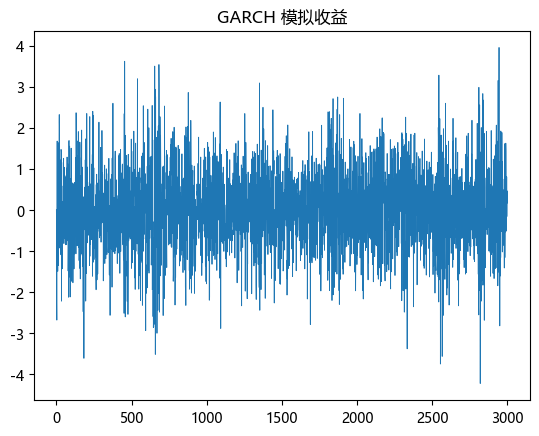

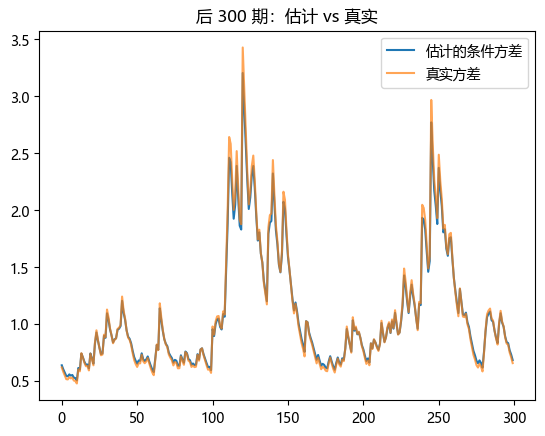

In [9]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(408)
n = 3000
omega, alpha, beta = 0.05, 0.10, 0.85
h = np.ones(n)
eps = np.zeros(n)
for t in range(1, n):
    h[t] = omega + alpha * eps[t - 1] ** 2 + beta * h[t - 1]
    eps[t] = np.sqrt(h[t]) * rng.normal()

def garch_h(params, r):
    w, a, b = params
    out = np.empty(len(r))
    cur = np.var(r)
    for t, e in enumerate(r):
        out[t] = cur
        cur = w + a * e * e + b * cur
    return out

def nll(params, r):
    w, a, b = params
    if w <= 0 or a + b >= 0.999:
        return 1e9
    hh = garch_h(params, r)[1:]
    rr = r[1:]
    if np.any(hh <= 0):
        return 1e9
    return 0.5 * np.sum(np.log(hh) + rr * rr / hh)

res = minimize(nll, [0.1, 0.1, 0.8], args=(eps,), method="L-BFGS-B",
               bounds=[(1e-6, 2), (1e-6, 0.98), (1e-6, 0.98)])
w, a, b = res.x
hh = garch_h(res.x, eps)

print("估计参数", res.x.round(3))
print("持续性、长期方差", round(a + b, 3), round(w / (1 - a - b), 3))
print("下一期方差预测", round(w + a * eps[-1] ** 2 + b * hh[-1], 3))

plt.plot(eps, linewidth=0.6)
plt.title("GARCH 模拟收益")
plt.show()

plt.plot(hh[-300:], label="估计的条件方差")
plt.plot(h[-300:], label="真实方差", alpha=0.7)
plt.legend()
plt.title("后 300 期：估计 vs 真实")
plt.show()



**读数与应用**：估计参数应该接近 0.05、0.10、0.85，持续性接近 0.95，长期方差接近 1。条件方差图会显示“成簇”：大波动后跟一段高方差，再慢慢回落。真实数据里，参数估计对样本段很敏感；要报告训练段、测试段和预测损失，而不是只报参数。

**常见错误**：

1. 用平方收益当“方差”。平方收益是方差的含噪观测，不是方差本身。
2. 用全样本估参数，再回测同一段。参数用了未来信息。
3. 把年化波动率和日方差混用。$\sqrt{252}$ 是年化标准差，不是方差。
4. 只看样本内拟合。GARCH 的价值在样本外预测，尤其是风险预算和仓位。

**停下来想一想**：若昨天冲击是 $+3$ 而不是 $-3$，标准 GARCH 的预测会变吗？

<details><summary>对照你的思路</summary>

不会，公式只看 $\epsilon^2$。若市场在下跌后波动增加得更多，需要非对称模型（GJR-GARCH、EGARCH），让负冲击的系数更大。先用对称模型算通，再比较非对称模型是否真的改善了样本外损失。

</details>

### 8.7 和谁比：常数方差与 EWMA

GARCH 不是唯一的波动率模型。至少要和两个基准比：

| 模型 | 预测 | 特点 |
|---|---|---|
| 常数方差 | 用训练段方差，一直不变 | 最保守的基准 |
| EWMA | $h_t=\lambda h_{t-1}+(1-\lambda)\epsilon_{t-1}^2$ | 反应快，但没有长期中枢 |
| GARCH(1,1) | 均值回归到长期方差 | 多了一个“中枢” |

比较时用同一段样本外数据、同一个损失函数（如 $\ln h+\epsilon^2/h$），报告损失差和不确定性。如果 GARCH 只比常数方差好一点点，先检查参数估计和样本段，不要急着说“波动率可预测”。

---



## 9. 频谱与周期：怎样从数据里量出节奏

### 9.1 频率与周期

把一条序列看成不同频率正弦波的叠加。频率 $f$ 是“每个样本多少个周期”，周期是

$$T=\frac{1}{f}.$$

离散傅里叶变换（DFT）把长度为 $N$ 的序列分解成 $N$ 个频率分量：

$$X_k=\sum_{n=0}^{N-1}x_n e^{-2\pi i kn/N}.$$

$|X_k|^2$ 是第 $k$ 个频率的功率。FFT 是 DFT 的快速算法。

### 9.2 手算

40 个等间隔样本，若重复 8 次，则每个样本 $8/40=0.2$ 个周期，周期 $1/0.2=5$ 个样本。

### 9.3 陷阱

- **采样**：分钟数据里的“周期 5”是 5 分钟，不是 5 天；换成日线要重新算。
- **混叠**：采样太粗，高频信号会伪装成低频。
- **窗口**：加窗会改变峰值；不做窗时，端点突变会泄漏到其他频率。
- **非平稳**：趋势、结构突变、休市安排都会造峰；峰值不等于可交易周期。

### 9.4 代码：找周期



前三个峰对应的周期 [ 4.71  5.   12.  ]


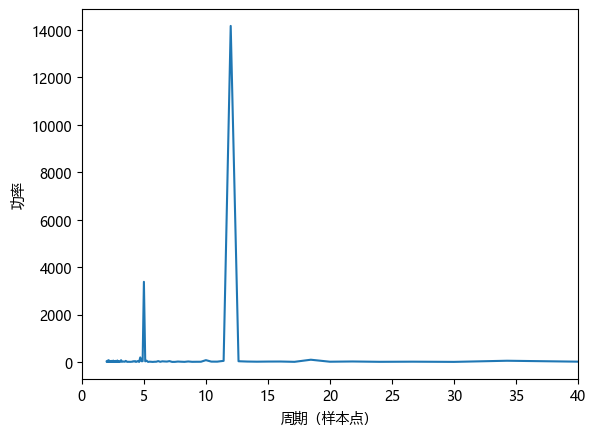

In [10]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(409)
n = 240
t = np.arange(n)
wave = (
    np.cos(2 * np.pi * t / 12)
    + 0.5 * np.cos(2 * np.pi * t / 5)
    + 0.3 * rng.normal(size=n)
)

freq = np.fft.rfftfreq(n)
power = np.abs(np.fft.rfft(wave - wave.mean())) ** 2
order = np.argsort(power[1:])[-3:] + 1

print("前三个峰对应的周期", (1 / freq[order]).round(2))

plt.plot(1 / freq[1:], power[1:])
plt.xlim(0, 40)
plt.xlabel("周期（样本点）")
plt.ylabel("功率")
plt.show()



**读数与应用**：前三个峰里应该能看到 12 和 5 附近。真实价格里的峰，可能来自交易时段安排（比如每天固定时间开盘）、周内效应、或数据采样，而不是“价格每 5 分钟循环一次”。看到峰之后，先做一个“保留时段、打乱价格”的对照，看看峰还在不在。

**常见错误**：

1. 把 FFT 的峰值直接当交易周期。峰可能只是采样或休市造成的。
2. 用不同长度的窗口比较功率。功率会随样本长度变化。
3. 忽略趋势。趋势会把能量堆到低频，掩盖真正的周期。

**停下来想一想**：如果一段数据里既有上升趋势，又有 5 天周期，FFT 会看到什么？

<details><summary>对照你的思路</summary>

趋势会在低频产生很大的功率，可能盖过 5 天周期；直接对原始价格做 FFT，主峰往往是趋势，不是周期。通常先去掉趋势（差分或回归），再做频谱；或者对收益做，而不是对价格做。

</details>

### 9.5 一个对照实验

看到频谱峰值后，做一个“保留时段、打乱价格”的对照：

1. 保留原来的时间戳和休市安排；
2. 把收益随机打乱，重新累积成价格；
3. 再做一次 FFT。

如果对照也出现同一个峰，说明峰来自采样/时段，不是价格本身的周期。只有“真实数据有、对照没有”的峰，才值得进一步研究。

---



## 本章小结

### 一张表

| 概念 | 公式/做法 | 用途 |
|---|---|---|
| 对数收益 | $r_t=\ln(P_t/P_{t-1})$ | 可加、对称 |
| 随机漫步 | $P_t=P_{t-1}+\epsilon_t$ | 基准模型 |
| 方差缩放 | $\operatorname{Var}(P_t)=t\sigma^2$ | 时间尺度换算 |
| ADF | $\Delta x_t=\alpha+\beta x_{t-1}+\dots$ | 单位根检验 |
| ACF | $\rho_k=\operatorname{Cov}(x_t,x_{t-k})/\operatorname{Var}(x_t)$ | 记忆长度 |
| AR(1) | $x_t=c+\phi x_{t-1}+\epsilon_t$ | 均值回归 |
| 半衰期 | $\ln0.5/\ln\phi$ | 回归速度 |
| 协整 | $y_t-\beta x_t$ 平稳 | 配对交易 |
| GARCH | $h_t=\omega+\alpha\epsilon_{t-1}^2+\beta h_{t-1}$ | 波动率预测 |
| 长期方差 | $\omega/(1-\alpha-\beta)$ | 波动率中枢 |

### 八句话

1. 价格是水平，收益是变化；统计检验通常对收益做。
2. 随机漫步的路径像趋势，但下一步不可预测。
3. 方差按时间线性增长，标准差按 $\sqrt t$ 增长。
4. 价格通常不平稳，收益通常近似平稳；ADF 要用对对象。
5. 收益的 ACF 接近 0，平方收益的 ACF 可能很大。
6. AR(1) 的 $\phi$ 越接近 1，回归越慢；半衰期不是持仓时间。
7. 协整看的是“差距会不会回来”，不是“相关系数高不高”。
8. GARCH 预测的是方差，不是方向；它的价值在风险预算，不在择时。

---

## 本章习题

**1.** 价格 100 → 103 → 99。求两段对数收益和总对数收益。

**2.** 随机漫步每步标准差 2，100 步后价格的标准差是多少？

**3.** AR(1) 的 $c=1,\phi=0.9$。求长期均值和半衰期。

**4.** 为什么 ADF 检验不能用 1.96 当 5% 临界值？

**5.** 序列 $(1,-1,1,-1)$ 的一阶自相关是多少？

**6.** GARCH(1,1) 的 $\omega=0.05,\alpha=0.1,\beta=0.85$，当前 $h=1$，昨天冲击 $-2$。求下一期方差和长期方差。

**7.** 若 $y=2x+u$，$u$ 有单位根，能不能做价差交易？为什么？

**8.** 240 个样本，FFT 峰值在周期 12。对应的频率是多少？这段数据里大约有多少个完整周期？

<details><summary>参考答案</summary>

**1.** $\ln(103/100)\approx0.02956$，$\ln(99/103)\approx-0.03922$，总对数收益 $\ln(99/100)\approx-0.01005$。

**2.** $\operatorname{SD}=2\sqrt{100}=20$。

**3.** 长期均值 $1/(1-0.9)=10$；半衰期 $\ln0.5/\ln0.9\approx6.58$ 期。

**4.** ADF 的统计量在零假设下服从 Dickey-Fuller 分布，不是标准正态或 t；临界值取决于样本量、是否含常数/趋势、滞后阶数。1.96 是正态的双侧 5% 门槛，用在这里会严重高估显著性。

**5.** 均值 0，分子 $(-1)+(-1)+(-1)=-3$，分母 4，$\rho_1=-0.75$。

**6.** $h_{next}=0.05+0.1\times4+0.85\times1=1.30$；长期方差 $0.05/(1-0.95)=1.0$。

**7.** 不能按均值回归做。$u$ 有单位根，价差会随机漫步，偏离可能永远不回来；除非有额外的基本面锚，否则不是统计套利。

**8.** 频率 $f=1/12$ 周期/样本；240 个样本约有 $240/12=20$ 个完整周期。

</details>

---

## 参考资料

- Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice*（第 3 版，https://otexts.com/fpp3/）。
- Bollerslev, T. (1986). *Generalized Autoregressive Conditional Heteroskedasticity*.
- Engle, R. F. & Granger, C. W. J. (1987). *Co-integration and Error Correction*.
- Tsay, R. S. *Analysis of Financial Time Series*（时间序列与 GARCH 的标准教材）。
